# Tabular Model Benchmark Across Four Datasets

**Family:** End-to-end project | **Dataset:** `multiple` | **Task:** classification

Compare six model families on four datasets with repeated cross validation and report average ranks, not a single winner.

## Table of Contents

- 1. Problem statement
- 2. Business or research context
- 3. Dataset documentation
- 4. Research references
- 5. Exploratory analysis
- 6. Preprocessing
- 7. Model selection
- 8. Model training
- 9. Evaluation
- 10. Comparison
- 11. Interpretation
- 12. Limitations
- 13. Final recommendations

## 1. Problem statement

Which model families work best across several small tabular problems?

## 2. Business or research context

Claims such as 'trees beat neural networks on tabular data' depend on datasets and tuning. We run a small, transparent test on four datasets with equal, light tuning and report spread. It cannot settle the claim of Grinsztajn et al., which used many more datasets.

## 3. Dataset documentation

Four datasets from the repository registry: `breast_cancer`, `wine`, `digits` and `telco_churn` (see their notebooks for licences). Each dataset is evaluated with 5-fold stratified cross validation repeated 2 times. The metric is macro F1 (PR-AUC for Telco is in the churn project).

## 4. Research references

Verification status is from the build environment on 2026-11-17. Entries marked *not verified* must be checked before citing.

- Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022). *Why do tree-based models still outperform deep learning on tabular data?*. NeurIPS 2022 Datasets and Benchmarks; arXiv:2207.08815. https://arxiv.org/abs/2207.08815 Verification: arXiv abstract page 2026-11-17
- Breiman, L. (2001). *Random Forests*. Machine Learning 45(1):5-32. https://doi.org/10.1023/A:1010933404324 Verification: Crossref 2026-11-17
- Friedman, J. H. (2001). *Greedy function approximation: A gradient boosting machine*. The Annals of Statistics 29(5):1189-1232. https://doi.org/10.1214/aos/1013203451 Verification: Crossref 2026-11-17
- Cortes, C. and Vapnik, V. (1995). *Support-vector networks*. Machine Learning 20(3):273-297. https://doi.org/10.1007/BF00994018 Verification: Crossref 2026-11-17

Grinsztajn et al. motivate the question. The other papers define the model families.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline, build_preprocessor
from ml_lab.evaluation import evaluate_estimator, internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
PROJECT_ID = "tabular_model_benchmark"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
names = ["breast_cancer", "wine", "digits", "telco_churn"]
data = {n: load_dataset(n) for n in names}
print({n: data[n].X.shape for n in names})

{'breast_cancer': (569, 30), 'wine': (178, 13), 'digits': (1797, 64), 'telco_churn': (7043, 19)}


## 5. Exploratory analysis

Size, number of classes and missing values per dataset.

In [3]:
display(pd.DataFrame({n: {"rows": len(b.X), "features": b.X.shape[1], "classes": b.y.nunique(), "minority_share": float(b.y.value_counts(normalize=True).min()), "missing": int(b.X.isna().sum().sum())} for n, b in data.items()}).T)

,rows,features,classes,minority_share,missing
breast_cancer,569.0,30.0,2.0,0.372583,0.0
wine,178.0,13.0,3.0,0.269663,0.0
digits,1797.0,64.0,10.0,0.096828,0.0
telco_churn,7043.0,19.0,2.0,0.265370,11.0


## 6. Preprocessing

Each model sits in a pipeline with imputation, encoding and (for models that need it) scaling, fitted inside each fold. Telco is limited to the first 4000 rows to keep the run short, which is stated here and in the metadata.

In [4]:
from sklearn.model_selection import RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
from types import SimpleNamespace
data["telco_churn"] = SimpleNamespace(X=data["telco_churn"].X.iloc[:4000], y=data["telco_churn"].y.iloc[:4000])

## 7. Model selection

Six families with fixed, light settings (no per-dataset search): logistic regression, k nearest neighbours, RBF SVM, random forest, histogram gradient boosting and MLP.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
models = {"logistic": (LogisticRegression(max_iter=2000), True), "knn": (KNeighborsClassifier(7), True), "svm_rbf": (SVC(C=3), True),
          "random_forest": (RandomForestClassifier(200, min_samples_leaf=2, n_jobs=2, random_state=SEED), False),
          "hist_gb": (HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1, max_iter=150, random_state=SEED), False),
          "mlp": (MLPClassifier((64,), alpha=1e-3, max_iter=400, early_stopping=True, random_state=SEED), True)}
print(list(models))

['logistic', 'knn', 'svm_rbf', 'random_forest', 'hist_gb', 'mlp']


## 8. Model training

Score every model on every dataset.

In [6]:
import time
scores, spread = {}, {}
for dn, b in data.items():
    for mn, (m, sc) in models.items():
        t = time.time()
        s = cross_val_score(make_model_pipeline(b.X, clone(m), scale=sc), b.X, b.y, cv=cv, scoring="f1_macro")
        scores[(dn, mn)], spread[(dn, mn)] = s.mean(), s.std(ddof=1)
    print(dn, "done")

breast_cancer done


wine done


digits done


telco_churn done


## 9. Evaluation

Macro F1 table, with the standard deviation over folds, and average rank per model (1 is best).

In [7]:
tab = pd.Series(scores).unstack().loc[names, list(models)]
sd = pd.Series(spread).unstack().loc[names, list(models)]
display(tab.round(3)); display(sd.round(3))
ranks = tab.rank(axis=1, ascending=False)
avg_rank = ranks.mean().sort_values()
display(avg_rank.round(2).to_frame("average rank"))
METRICS = {f"avg_rank_{k}": float(v) for k, v in avg_rank.items()}
METRICS["best_model_by_avg_rank_index"] = float(list(models).index(avg_rank.index[0]))
CONFIG = {"cv": "repeated stratified 5x2", "datasets": names, "telco_rows": 4000}
EXTRA = {"macro_F1": tab.round(4).reset_index().to_dict("records"), "best_model_by_avg_rank": avg_rank.index[0]}
ALGORITHM = "benchmark of six model families"

record = ExperimentRecord(notebook=PROJECT_ID, family="project", algorithm=ALGORITHM, dataset="multiple", task="classification", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,logistic,knn,svm_rbf,random_forest,hist_gb,mlp
breast_cancer,0.973,0.965,0.979,0.950,0.961,0.905
wine,0.989,0.969,0.980,0.983,0.975,0.918
digits,0.969,0.972,0.984,0.975,0.972,0.957
telco_churn,0.727,0.709,0.707,0.722,0.727,0.722


,logistic,knn,svm_rbf,random_forest,hist_gb,mlp
breast_cancer,0.016,0.016,0.017,0.018,0.017,0.040
wine,0.015,0.036,0.024,0.020,0.036,0.057
digits,0.009,0.006,0.007,0.006,0.005,0.012
telco_churn,0.016,0.013,0.010,0.014,0.016,0.020


,average rank
logistic,2.25
svm_rbf,2.75
random_forest,3.25
hist_gb,3.50
knn,4.00
mlp,5.25


saved: experiments/results/tabular_model_benchmark.json


,metric
avg_rank_logistic,2.25
avg_rank_svm_rbf,2.75
avg_rank_random_forest,3.25
avg_rank_hist_gb,3.50
avg_rank_knn,4.00
avg_rank_mlp,5.25
best_model_by_avg_rank_index,0.00


## 10. Comparison

Plot the scores per dataset and mark differences smaller than one fold standard deviation.

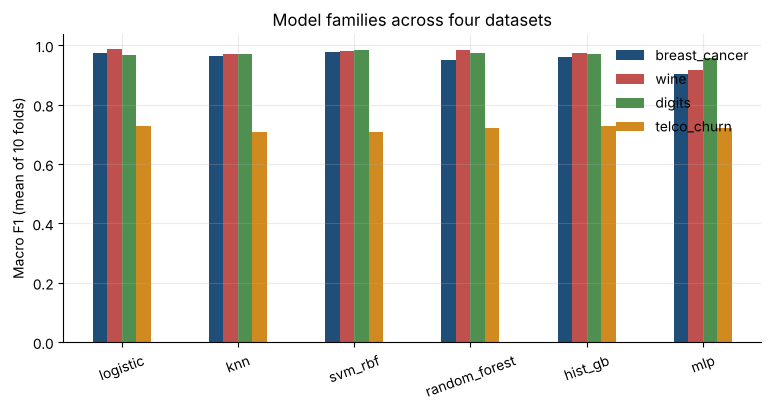

models within one fold std of the best model, per dataset: {'breast_cancer': np.int64(3), 'wine': np.int64(5), 'digits': np.int64(1), 'telco_churn': np.int64(4)}


In [8]:
fig, ax = plt.subplots(figsize=(9, 4)); tab.T.plot.bar(ax=ax, rot=20); ax.set_ylabel("Macro F1 (mean of 10 folds)"); ax.set_title("Model families across four datasets"); save_figure(fig, PROJECT_ID, "benchmark"); plt.show()
within = (tab.max(axis=1) - tab.sub(tab.max(axis=1), axis=0).abs().min(axis=1))
close = ((tab.max(axis=1).values[:, None] - tab.values) < sd.values).sum(axis=1)
print("models within one fold std of the best model, per dataset:", dict(zip(names, close)))

## 11. Interpretation

With four datasets the ranking is fragile. The count of models within one fold standard deviation of the best shows how often the winner is clear.

In [9]:
print("rank table (1 is best):"); display(ranks.astype(int))

rank table (1 is best):


,logistic,knn,svm_rbf,random_forest,hist_gb,mlp
breast_cancer,2,3,1,5,4,6
wine,1,5,3,2,4,6
digits,5,3,1,2,4,6
telco_churn,1,5,6,4,2,3


## 12. Limitations

Four small datasets, fixed light settings, one metric, Telco shortened to 4000 rows. Differences of a few thousandths are noise. This benchmark cannot confirm or refute large scale benchmark claims.

## 13. Final recommendations

Start with a regularised linear model and a tree ensemble as baselines on any new tabular problem, tune the best two, and decide with repeated cross validation and spread, not a single run.